# Lightweight CNN (Hussein et al.) on PneumoniaMNIST (binary: Normal vs Pneumonia)

Implementation of **Lightweight deep CNN-based models for early detection of COVID-19 patients from chest X-ray images** (Hussein et al., Expert Systems With Applications 223, 2023), trained **from scratch** and written exactly from Table 2 (architecture), Table 3 (hyper-parameters), Eq. (1) (normalisation to [-1, 1]), Eq. (8) (class weights) and Algorithm 1. Input 1x112x112; 2 classes use the paper's binary head (1 neuron + sigmoid, 591,903 parameters), more classes use the softmax head (3 classes: 592,929 parameters). The paper gives no source code, so the layers are written from its tables.

Outputs: train / val / test loss, accuracy, F1, precision, recall curves; confusion matrices; classification report; ROC; parameters and forward/backward FLOPs.

In [1]:
!pip install -q medmnist seaborn scikit-learn

## 1. Config

In [2]:
import os, math, time, numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
from sklearn.metrics import classification_report

# ---------------- model ----------------
IMG_SIZE     = 112      # paper: 112 x 112 grayscale
# ---------------- training (Table 3 of the paper) ----------------
BATCH_SIZE   = 6        # as requested (paper used 32)
EPOCHS       = 100      # paper: 100
LR           = 0.001    # paper: Adam, lr 0.001, beta_1 0.9, beta_2 0.999 (no weight decay)
SEED         = 42
NUM_WORKERS = 0   # (unused: data is served from memory)
# ---------------- switches (all OFF = plain training) ----------------
USE_AUGMENTATION  = False   # paper: no augmentation
USE_CLASS_WEIGHTS = True    # paper: class weights w_i = T / (c * n_i) (Eq. 8), computed on the training set

AVG = "binary"             # averaging for precision / recall / F1
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DEVICE = device
print("device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "")

device: cuda | Tesla T4


## 2. Data (MedMNIST+, loaded at 224x224 and resized to 112x112 grayscale, official train / val / test splits)

In [3]:
import medmnist
from medmnist import PneumoniaMNIST
def load(split):
    d = PneumoniaMNIST(split=split, download=True, size=224)          # 112 does not exist in MedMNIST: load 224 and resize to 112
    x = torch.from_numpy(d.imgs.astype(np.float32)).unsqueeze(1)
    x = F.interpolate(x, size=(IMG_SIZE, IMG_SIZE), mode="bilinear", antialias=True, align_corners=False)
    return x.round().clamp(0, 255).squeeze(1).numpy().astype(np.uint8), d.labels.reshape(-1).astype(np.int64)
Xtr, Ytr = load("train"); Xva, Yva = load("val"); Xte, Yte = load("test")
CLASS_NAMES = ["Normal", "Pneumonia"]; NUM_CLASSES = 2
print("shapes:", Xtr.shape, Xva.shape, Xte.shape)
for n, y in [("train", Ytr), ("val", Yva), ("test", Yte)]:
    print(f"{n:5s} class counts [Normal, Pneumonia]:", np.bincount(y, minlength=2))

100%|██████████| 214M/214M [01:43<00:00, 2.08MB/s] 


shapes: (4708, 112, 112) (524, 112, 112) (624, 112, 112)
train class counts [Normal, Pneumonia]: [1214 3494]
val   class counts [Normal, Pneumonia]: [135 389]
test  class counts [Normal, Pneumonia]: [234 390]


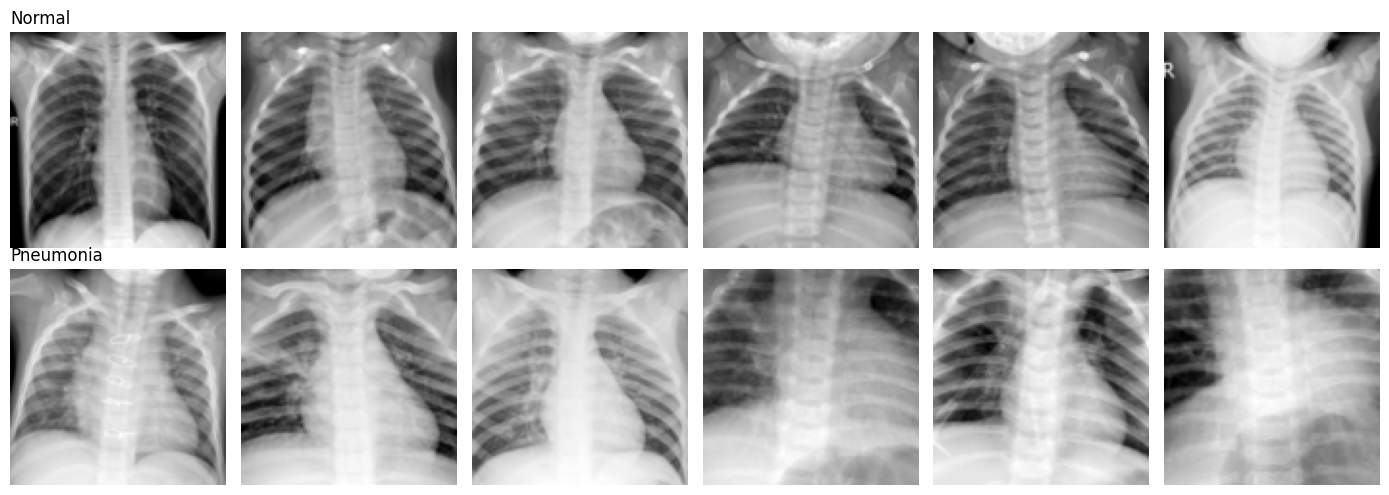

In [4]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(2, 6, figsize=(14, 5))
for cls in [0, 1]:
    for a, i in zip(ax[cls], np.where(Ytr == cls)[0][:6]):
        a.imshow(Xtr[i], cmap="gray"); a.axis("off")
    ax[cls][0].set_title(CLASS_NAMES[cls], loc="left")
plt.tight_layout(); plt.show()

## 3. Lightweight CNN (Table 2 / Fig. 3 of the paper)

In [5]:
import torch, torch.nn as nn, torch.nn.functional as F


class PoolSame(nn.Module):
    """Keras/TensorFlow padding='same' pooling (output = ceil(in / stride); padding split with the extra row/col at the end).
    Max pooling is padded with -inf, average pooling ignores the padded cells (as TensorFlow does)."""
    def __init__(self, kind, k, s):
        super().__init__(); self.kind, self.k, self.s = kind, k, s
    def forward(self, x):
        H, W = x.shape[-2:]
        oh, ow = -(-H // self.s), -(-W // self.s)
        ph, pw = max((oh - 1) * self.s + self.k - H, 0), max((ow - 1) * self.s + self.k - W, 0)
        pad = (pw // 2, pw - pw // 2, ph // 2, ph - ph // 2)
        if self.kind == "max":
            return F.max_pool2d(F.pad(x, pad, value=float("-inf")), self.k, self.s)
        num = F.avg_pool2d(F.pad(x, pad), self.k, self.s, divisor_override=1)
        cnt = F.avg_pool2d(F.pad(torch.ones(1, 1, H, W, device=x.device, dtype=x.dtype), pad), self.k, self.s, divisor_override=1)
        return num / cnt


class LightweightDCNN(nn.Module):
    """Lightweight CNN of Hussein et al., 'Lightweight deep CNN-based models for early detection of COVID-19 patients from chest X-ray images'
    (Expert Syst. Appl. 223, 2023), implemented exactly as Table 2 / Fig. 3:
      [Conv3x3(11)+ELU] x2 -> MaxPool 3x3/3 'same' -> Dropout 0.4
      [Conv3x3(17)+ELU] x2 -> MaxPool 3x3/3 'same' -> Dropout 0.4
      [Conv3x3(23)+ELU] x2 -> AvgPool 2x2/2 'same' -> Dropout 0.4
      Flatten -> Dense 512 + ELU -> Dropout 0.25 -> output
    All convolutions: stride 1, padding 'same', HeNormal init. Input 1 x 112 x 112.
    Output layer: 1 neuron + sigmoid for 2 classes (binary model, 591,903 params) or C neurons + softmax (3 classes: 592,929 params).
    The network returns raw logits (sigmoid / softmax are applied in the loss and in the metrics)."""
    def __init__(self, num_classes, in_chans=1, img_size=112):
        super().__init__()
        def conv(i, o): return [nn.Conv2d(i, o, 3, 1, 1), nn.ELU(alpha=1.0)]
        self.features = nn.Sequential(
            *conv(in_chans, 11), *conv(11, 11), PoolSame("max", 3, 3), nn.Dropout(0.4),
            *conv(11, 17), *conv(17, 17), PoolSame("max", 3, 3), nn.Dropout(0.4),
            *conv(17, 23), *conv(23, 23), PoolSame("avg", 2, 2), nn.Dropout(0.4))
        with torch.no_grad():
            n_flat = self.features(torch.zeros(1, in_chans, img_size, img_size)).numel()     # 7*7*23 = 1127 for 112 x 112
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(n_flat, 512), nn.ELU(alpha=1.0), nn.Dropout(0.25),
                                        nn.Linear(512, 1 if num_classes == 2 else num_classes))
        for m in self.modules():
            if isinstance(m, (nn.Conv2d, nn.Linear)):          # Keras HeNormal (truncated normal, std = sqrt(2 / fan_in)), zero bias
                fan_in = m.weight[0].numel()
                nn.init.trunc_normal_(m.weight, 0.0, (2.0 / fan_in) ** 0.5, a=-2 * (2.0 / fan_in) ** 0.5, b=2 * (2.0 / fan_in) ** 0.5)
                nn.init.zeros_(m.bias)
    def forward(self, x):
        return self.classifier(self.features(x))


class AsTwoLogits(nn.Module):
    """Wraps the single-logit binary model so that softmax([0, z]) == [1 - sigmoid(z), sigmoid(z)].
    Cross-entropy on these two logits equals the paper's binary cross-entropy (Eq. 6) on the sigmoid output, so the training / metric / ROC code
    is shared with the multiclass case. It adds no parameters."""
    def __init__(self, net):
        super().__init__(); self.net = net
    def forward(self, x):
        z = self.net(x)
        return torch.cat([torch.zeros_like(z), z], 1)


def make_model(num_classes, img_size=112):
    net = LightweightDCNN(num_classes, 1, img_size)
    return AsTwoLogits(net) if num_classes == 2 else net


class KerasClassWeightedCE(nn.Module):
    """Keras `class_weight` semantics: every sample's loss is multiplied by the weight of its class and the batch MEAN is taken
    (PyTorch's CrossEntropyLoss(weight=...) would divide by the sum of weights instead)."""
    def __init__(self, class_weights=None):
        super().__init__()
        self.register_buffer("w", None if class_weights is None else torch.as_tensor(class_weights, dtype=torch.float32))
    def forward(self, out, y):
        l = F.cross_entropy(out, y, reduction="none")
        return (l * self.w[y]).mean() if self.w is not None else l.mean()

## 4. Training utilities

In [6]:
import math, time, copy, random, numpy as np, torch, torch.nn as nn, torch.nn.functional as F
from sklearn.metrics import precision_recall_fscore_support, accuracy_score, roc_auc_score


def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


class ArrayLoader:
    """Serves batches from an in-memory uint8 array (N,H,W). No dataloader workers, no disk reads."""
    def __init__(self, X, Y, bs, shuffle=False, augment=False, drop_last=False):
        self.X = torch.from_numpy(np.ascontiguousarray(X)).unsqueeze(1)
        self.Y = torch.from_numpy(np.asarray(Y)).long()
        self.bs, self.shuffle, self.augment, self.drop_last = bs, shuffle, augment, drop_last

    def __len__(self):
        n = len(self.X)
        return n // self.bs if self.drop_last else math.ceil(n / self.bs)

    def _aug(self, x):   # rotation +-10 deg, translation +-5%, scale 0.95-1.05, brightness/contrast. No flips.
        B, d = x.shape[0], x.device
        ang = (torch.rand(B, device=d) * 2 - 1) * math.radians(10)
        s = 1 + (torch.rand(B, device=d) * 2 - 1) * 0.05
        tx, ty = [(torch.rand(B, device=d) * 2 - 1) * 0.1 for _ in range(2)]
        c, si = torch.cos(ang) * s, torch.sin(ang) * s
        theta = torch.stack([torch.stack([c, -si, tx], 1), torch.stack([si, c, ty], 1)], 1)
        x = F.grid_sample(x, F.affine_grid(theta, x.shape, align_corners=False), padding_mode="border", align_corners=False)
        br = torch.rand(B, 1, 1, 1, device=d) * 0.4 - 0.2
        ct = torch.rand(B, 1, 1, 1, device=d) * 0.4 + 0.8
        m = x.mean((1, 2, 3), keepdim=True)
        return ((x - m) * ct + m + br).clamp(0, 1)

    def __iter__(self):
        dev = DEVICE
        idx = torch.randperm(len(self.X)) if self.shuffle else torch.arange(len(self.X))
        for i in range(len(self)):
            b = idx[i * self.bs:(i + 1) * self.bs]
            x = self.X[b].to(dev, non_blocking=True).float().div_(255)
            if self.augment:
                x = self._aug(x)
            yield (x - 0.5) / 0.5, self.Y[b].to(dev, non_blocking=True)


def metrics(y, p, avg):
    pr, rc, f1, _ = precision_recall_fscore_support(y, p, average=avg, pos_label=1, zero_division=0)
    return dict(acc=accuracy_score(y, p), precision=pr, recall=rc, f1=f1)


def auc_score(y, prob):
    try:
        if prob.shape[1] == 2:
            return roc_auc_score(y, prob[:, 1])
        return roc_auc_score(y, prob, multi_class="ovr", average="macro")
    except ValueError:
        return float("nan")


@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    tot, n, ys, ps, pr = 0.0, 0, [], [], []
    for x, y in loader:
        out = model(x).float()
        tot += criterion(out, y).item() * x.size(0); n += x.size(0)
        ys.append(y.cpu()); ps.append(out.argmax(1).cpu()); pr.append(out.softmax(1).cpu())
    return tot / n, torch.cat(ys).numpy(), torch.cat(ps).numpy(), torch.cat(pr).numpy()


def fit(model, train_loader, val_loader, test_loader, criterion, device, avg, epochs=25, lr=1e-4, weight_decay=1e-4,
        optimizer="adamw", scheduler="cosine", gamma=0.995, warmup=0, patience=None, monitor="val_loss", use_amp=True,
        restore_best=True, ckpt="best_model.pt"):
    """optimizer: 'adamw' | 'adam'. scheduler: 'cosine' (optional linear warm-up) | 'exp' (ExponentialLR, gamma per epoch) | 'none'.
    patience: early stopping on `monitor` (e.g. 'val_loss' or 'val_f1'); None = NO early stopping (train all epochs).
    The weights of the best `monitor` epoch are restored at the end. The test set is logged each epoch for the curves only."""
    opt = (torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay) if optimizer == "adam"
           else torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay))
    if scheduler == "cosine":
        sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda e: (e + 1) / warmup if e < warmup
                                                  else 0.5 * (1 + math.cos(math.pi * (e - warmup) / max(1, epochs - warmup))))
    elif scheduler == "exp":
        sched = torch.optim.lr_scheduler.ExponentialLR(opt, gamma=gamma)
    else:
        sched = None
    use_amp = use_amp and device.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    keys = ["loss", "acc", "f1", "precision", "recall"]
    hist = {f"{s}_{k}": [] for s in ["train", "val", "test"] for k in keys}
    hist["lr"] = []
    lower_better = monitor.endswith("loss")
    best, best_state, best_ep, bad = (float("inf") if lower_better else -float("inf")), None, 0, 0
    for ep in range(1, epochs + 1):
        t0 = time.time(); model.train()
        tot, n, ys, ps = 0.0, 0, [], []
        for x, y in train_loader:
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, enabled=use_amp):
                out = model(x)
            loss = criterion(out.float(), y)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            scaler.step(opt); scaler.update()
            tot += loss.item() * x.size(0); n += x.size(0)
            ys.append(y.cpu()); ps.append(out.argmax(1).detach().cpu())
        tr = (tot / n, torch.cat(ys).numpy(), torch.cat(ps).numpy())
        vl, vy, vp, _ = evaluate(model, val_loader, criterion)
        sl, sy, sp, _ = evaluate(model, test_loader, criterion)          # monitoring only, never used for selection
        for name, (l, y, p) in [("train", tr), ("val", (vl, vy, vp)), ("test", (sl, sy, sp))]:
            hist[f"{name}_loss"].append(l)
            for k, v in metrics(y, p, avg).items():
                hist[f"{name}_{k}"].append(v)
        hist["lr"].append(opt.param_groups[0]["lr"])
        if sched is not None: sched.step()
        cur = hist[monitor][-1]
        improved = cur < best if lower_better else cur > best
        if improved:
            best, best_ep, bad = cur, ep, 0
            best_state = copy.deepcopy(model.state_dict()); torch.save(best_state, ckpt)
        else:
            bad += 1
        print(f"Ep {ep:02d}/{epochs} | {time.time()-t0:5.1f}s | loss tr {tr[0]:.4f} val {vl:.4f} test {sl:.4f} | "
              f"F1 tr {hist['train_f1'][-1]:.3f} val {hist['val_f1'][-1]:.3f} test {hist['test_f1'][-1]:.3f}"
              + ("  *best*" if improved else (f"  (no improvement {bad}/{patience})" if patience else "")))
        if patience and bad >= patience:
            print(f"Early stopping at epoch {ep}: {monitor} did not improve for {patience} epochs (best epoch {best_ep}).")
            break
    print(f"Best {monitor} = {best:.4f} at epoch {best_ep}" + ("; restoring those weights." if restore_best else "; keeping the LAST-epoch weights (RESTORE_BEST = False)."))
    if restore_best: model.load_state_dict(best_state)
    hist["best_epoch"] = best_ep
    return hist

In [7]:
set_seed(SEED)
cw = None
if USE_CLASS_WEIGHTS:                                   # Eq. (8): w_i = T / (c * n_i)
    cnt = np.bincount(Ytr, minlength=NUM_CLASSES); cw = cnt.sum() / (NUM_CLASSES * cnt)
    print("class weights:", dict(zip(CLASS_NAMES, np.round(cw, 4))))
criterion = KerasClassWeightedCE(cw).to(device)         # = binary CE (Eq. 6) for 2 classes, categorical CE (Eq. 7) otherwise

train_loader = ArrayLoader(Xtr, Ytr, BATCH_SIZE, shuffle=True, augment=USE_AUGMENTATION, drop_last=True)
val_loader   = ArrayLoader(Xva, Yva, BATCH_SIZE * 2)
test_loader  = ArrayLoader(Xte, Yte, BATCH_SIZE * 2)

model = make_model(NUM_CLASSES, IMG_SIZE).to(device)
print("output shape:", model(torch.randn(2, 1, IMG_SIZE, IMG_SIZE, device=device)).shape)

class weights: {'Normal': np.float64(1.939), 'Pneumonia': np.float64(0.6737)}
output shape: torch.Size([2, 2])


## 5. Parameters and FLOPs (forward / backward, per image and per batch)

In [8]:
import pandas as pd
from torch.utils.flop_counter import FlopCounterMode

def measure_flops(model, batch_size):
    """Forward and backward FLOPs of one training step (1 multiply-add = 2 FLOPs; matmul/conv/attention only)."""
    model.train(); model.zero_grad(set_to_none=True)
    x = torch.randn(batch_size, 1, IMG_SIZE, IMG_SIZE, device=device)
    with FlopCounterMode(display=False) as fc:
        out = model(x); fwd = fc.get_total_flops()
        out.float().sum().backward(); tot = fc.get_total_flops()
    model.zero_grad(set_to_none=True)
    return fwd, tot - fwd

def complexity_report(model):
    total = sum(p.numel() for p in model.parameters()); trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    fb, bb = measure_flops(model, BATCH_SIZE)
    f2, b2 = measure_flops(model, 2)               # per image = batch of 2 / 2 (BatchNorm needs >1 sample in train mode)
    f1, b1 = f2 / 2, b2 / 2
    fmt = lambda v: f"{v/1e6:.2f} M" if v < 1e9 else f"{v/1e9:.3f} G"
    rows = {"Total parameters": total, "Trainable parameters": trainable, "Non-trainable parameters": total - trainable,
            "Forward FLOPs / image": f1, "Backward FLOPs / image": b1, "Forward+Backward FLOPs / image": f1 + b1,
            f"Forward FLOPs / batch ({BATCH_SIZE})": fb, f"Backward FLOPs / batch ({BATCH_SIZE})": bb,
            f"Forward+Backward FLOPs / batch ({BATCH_SIZE})": fb + bb, "Forward MAdds / image (FLOPs/2, paper unit)": f1 / 2}
    df = pd.DataFrame({"value": rows}); df["readable"] = [fmt(v) for v in df["value"]]
    print(f"Input 1 x {IMG_SIZE} x {IMG_SIZE} | batch {BATCH_SIZE}"); display(df); df.to_csv("model_complexity.csv")

complexity_report(model)

Input 1 x 112 x 112 | batch 6


,value,readable
Total parameters,591903.0,0.59 M
Trainable parameters,591903.0,0.59 M
Non-trainable parameters,0.0,0.00 M
Forward FLOPs / image,46130448.0,46.13 M
Backward FLOPs / image,89777184.0,89.78 M
Forward+Backward FLOPs / image,135907632.0,135.91 M
Forward FLOPs / batch (6),276782688.0,276.78 M
Backward FLOPs / batch (6),538663104.0,538.66 M
Forward+Backward FLOPs / batch (6),815445792.0,815.45 M
"Forward MAdds / image (FLOPs/2, paper unit)",23065224.0,23.07 M


## 6. Training

Adam (lr 0.001, betas 0.9 / 0.999), constant learning rate, 100 epochs, fp32, no early stopping (paper, Table 3). Test metrics are logged each epoch **only** for the curves; the best checkpoint is chosen by **validation F1**.

In [9]:
set_seed(SEED)
model = make_model(NUM_CLASSES, IMG_SIZE).to(device)
history = fit(model, train_loader, val_loader, test_loader, criterion, device, AVG,
              epochs=EPOCHS, lr=LR, weight_decay=0.0, optimizer="adam", scheduler="none", monitor="val_loss", use_amp=False,
              ckpt="best_lightweight_dcnn.pt")

Ep 01/100 |   4.5s | loss tr 0.3421 val 0.1360 test 1.2401 | F1 tr 0.932 val 0.972 test 0.885  *best*
Ep 02/100 |   4.0s | loss tr 0.1941 val 0.2151 test 0.6817 | F1 tr 0.960 val 0.925 test 0.916
Ep 03/100 |   4.0s | loss tr 0.1632 val 0.1174 test 1.2982 | F1 tr 0.969 val 0.970 test 0.896  *best*
Ep 04/100 |   3.9s | loss tr 0.1455 val 0.1543 test 1.1962 | F1 tr 0.972 val 0.967 test 0.912
Ep 05/100 |   4.0s | loss tr 0.1489 val 0.1152 test 1.3141 | F1 tr 0.973 val 0.975 test 0.905  *best*
Ep 06/100 |   3.9s | loss tr 0.1443 val 0.0921 test 1.4742 | F1 tr 0.975 val 0.973 test 0.907  *best*
Ep 07/100 |   4.0s | loss tr 0.1398 val 0.1845 test 2.7649 | F1 tr 0.974 val 0.976 test 0.875
Ep 08/100 |   4.0s | loss tr 0.1401 val 0.1711 test 2.1270 | F1 tr 0.974 val 0.976 test 0.872
Ep 09/100 |   4.0s | loss tr 0.1206 val 0.1422 test 2.6236 | F1 tr 0.979 val 0.981 test 0.880
Ep 10/100 |   4.0s | loss tr 0.1289 val 0.1285 test 1.9890 | F1 tr 0.977 val 0.979 test 0.897
Ep 11/100 |   3.9s | loss tr

## 7. Curves

In [10]:
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, auc as sk_auc
from sklearn.preprocessing import label_binarize

def plot_history(h, avg_name):
    ep = range(1, len(h["train_loss"]) + 1)
    fig, ax = plt.subplots(2, 3, figsize=(18, 9)); ax = ax.ravel()
    for a, (k, t) in zip(ax, [("loss", "Loss"), ("acc", "Accuracy"), ("f1", f"F1 ({avg_name})"),
                              ("precision", f"Precision ({avg_name})"), ("recall", f"Recall ({avg_name})")]):
        for s, c in [("train", "tab:blue"), ("val", "tab:orange"), ("test", "tab:green")]:
            a.plot(ep, h[f"{s}_{k}"], label=s, color=c, lw=2)
        a.set_title(t); a.set_xlabel("epoch"); a.grid(alpha=.3); a.legend()
    ax[5].plot(ep, h["lr"], color="tab:red", lw=2); ax[5].set_title("Learning rate"); ax[5].set_xlabel("epoch"); ax[5].grid(alpha=.3)
    plt.tight_layout(); plt.savefig("training_curves.png", dpi=150); plt.show()

def plot_loss_only(h):
    ep = range(1, len(h["train_loss"]) + 1)
    plt.figure(figsize=(8, 5))
    for s, c in [("train", "tab:blue"), ("val", "tab:orange"), ("test", "tab:green")]:
        plt.plot(ep, h[f"{s}_loss"], label=f"{s} loss", color=c, lw=2)
    plt.xlabel("epoch"); plt.ylabel("loss"); plt.title("Train / Val / Test loss"); plt.grid(alpha=.3); plt.legend()
    plt.tight_layout(); plt.savefig("loss_curves.png", dpi=150); plt.show()

def plot_confusion(y, p, names, title, fname):
    n = len(names); cm = confusion_matrix(y, p, labels=range(n)); cmn = cm / cm.sum(1, keepdims=True).clip(min=1)
    w = max(11, 1.6 * n * 2)
    fig, ax = plt.subplots(1, 2, figsize=(w, max(4.5, 0.9 * n + 2.5)))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=names, yticklabels=names, ax=ax[0]); ax[0].set_title(f"{title} - counts")
    sns.heatmap(cmn, annot=True, fmt=".2f", cmap="Blues", xticklabels=names, yticklabels=names, ax=ax[1], vmin=0, vmax=1)
    ax[1].set_title(f"{title} - normalised by true class")
    for a in ax:
        a.set_xlabel("Predicted"); a.set_ylabel("True"); a.tick_params(axis="x", rotation=30)
    plt.tight_layout(); plt.savefig(fname, dpi=150); plt.show()

def plot_roc(y, prob, names, fname="roc_curves.png"):
    plt.figure(figsize=(6.5, 5.5))
    if len(names) == 2:
        fpr, tpr, _ = roc_curve(y, prob[:, 1]); plt.plot(fpr, tpr, lw=2, label=f"{names[1]} (AUC {sk_auc(fpr, tpr):.3f})")
    else:
        yb = label_binarize(y, classes=range(len(names)))
        for i, n in enumerate(names):
            fpr, tpr, _ = roc_curve(yb[:, i], prob[:, i]); plt.plot(fpr, tpr, lw=2, label=f"{n} (AUC {sk_auc(fpr, tpr):.3f})")
    plt.plot([0, 1], [0, 1], "k--", alpha=.5); plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
    plt.title("ROC (test)"); plt.legend(loc="lower right", fontsize=8); plt.grid(alpha=.3); plt.tight_layout()
    plt.savefig(fname, dpi=150); plt.show()

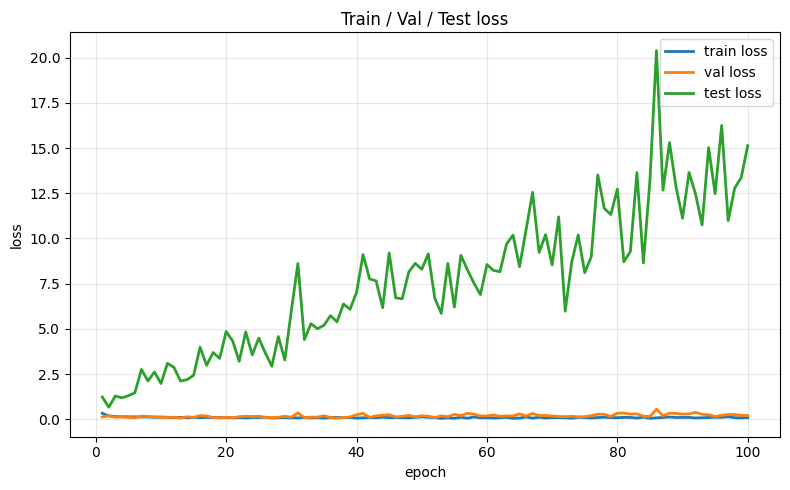

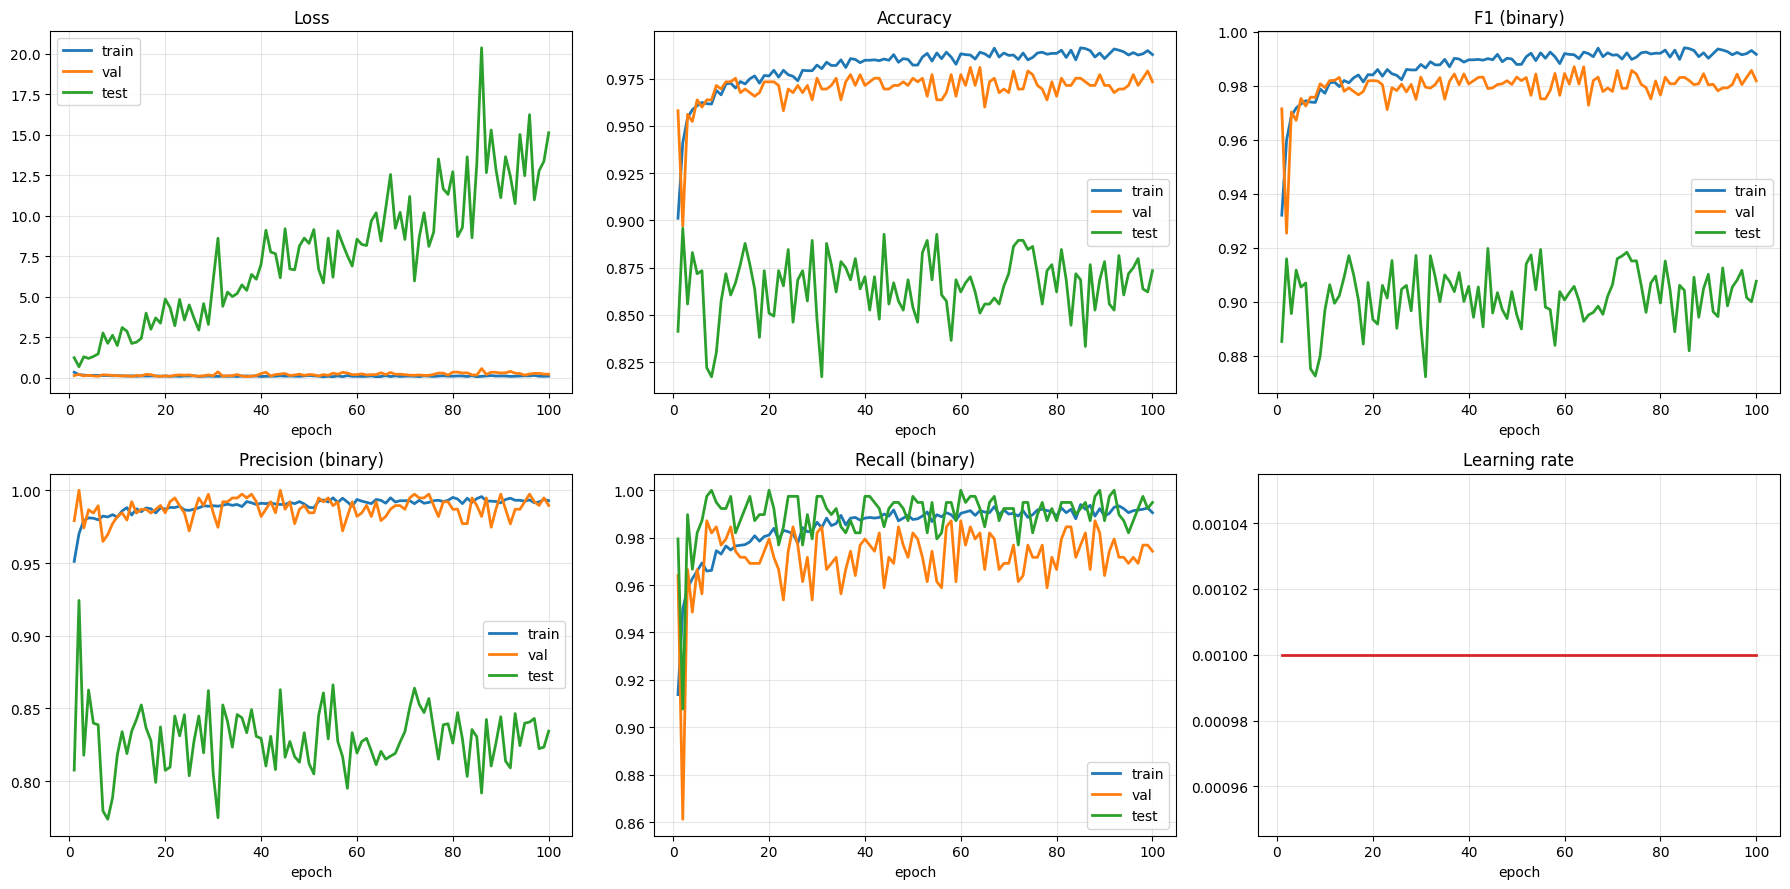

In [11]:
plot_loss_only(history)
plot_history(history, AVG)

## 8. Final evaluation (best-validation checkpoint)

In [12]:
import pandas as pd
res = {n: evaluate(model, l, criterion) for n, l in [("val", val_loader), ("test", test_loader)]}
rows = []
for n, (loss, y, p, prob) in res.items():
    m = metrics(y, p, AVG); m["loss"] = loss; m["auc"] = auc_score(y, prob); rows.append(pd.Series(m, name=n))
print(f"precision / recall / F1 = {AVG}-averaged")
print(pd.DataFrame(rows)[["loss", "acc", "precision", "recall", "f1", "auc"]].round(4))
_, ytest, ptest, probtest = res["test"]
print("\nTest classification report")
print(classification_report(ytest, ptest, target_names=CLASS_NAMES, digits=4, zero_division=0))

precision / recall / F1 = binary-averaged
        loss     acc  precision  recall      f1     auc
val   0.0693  0.9771     0.9948  0.9743  0.9844  0.9975
test  5.3961  0.8686     0.8333  0.9872  0.9038  0.9072

Test classification report
              precision    recall  f1-score   support

      Normal     0.9691    0.6709    0.7929       234
   Pneumonia     0.8333    0.9872    0.9038       390

    accuracy                         0.8686       624
   macro avg     0.9012    0.8291    0.8483       624
weighted avg     0.8843    0.8686    0.8622       624



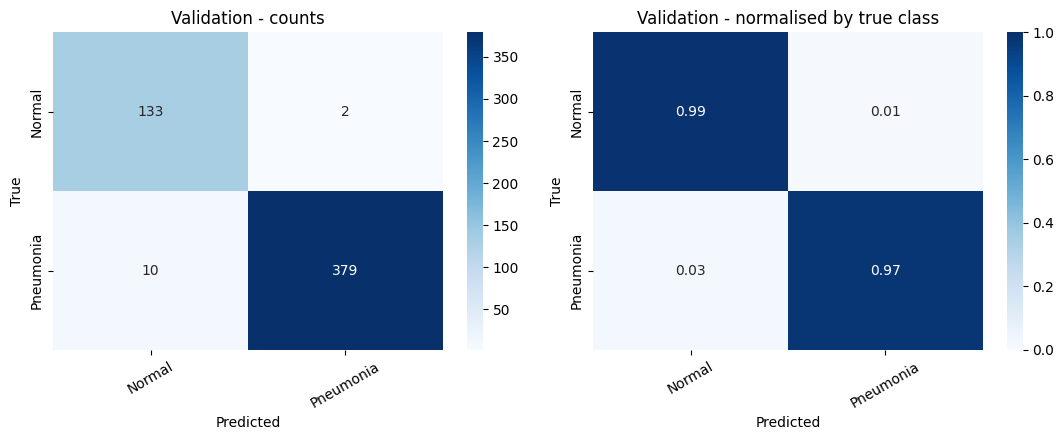

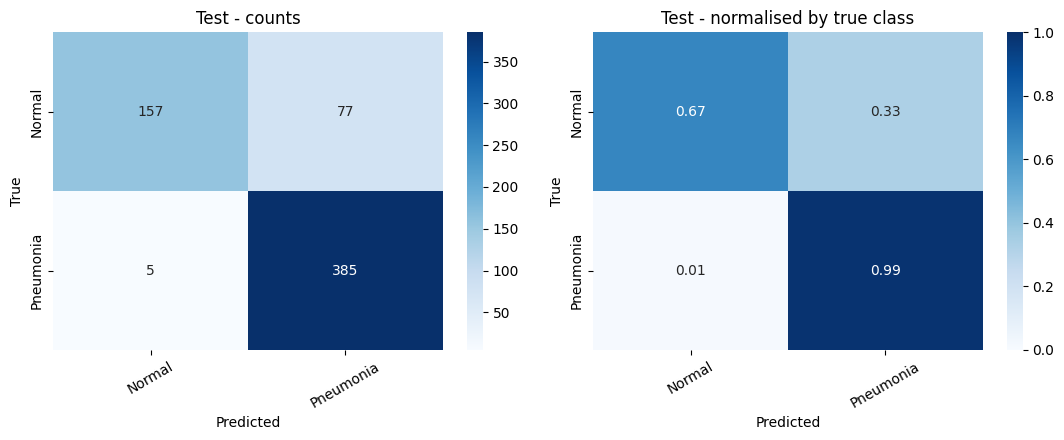

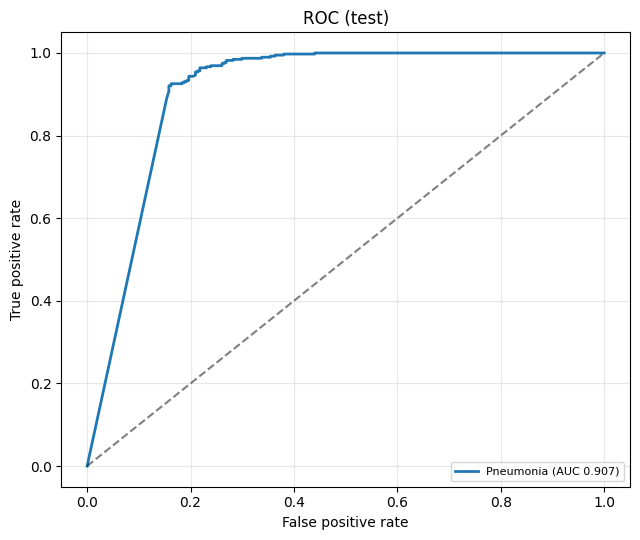

In [13]:
plot_confusion(res["val"][1], res["val"][2], CLASS_NAMES, "Validation", "confusion_val.png")
plot_confusion(ytest, ptest, CLASS_NAMES, "Test", "confusion_test.png")
plot_roc(ytest, probtest, CLASS_NAMES)

## Notes
- Everything follows the paper: Adam lr 0.001, 100 epochs, no augmentation, class weights w_i = T/(c*n_i) (Keras `class_weight` semantics), inputs scaled with (X-127.5)/127.5, 112x112 grayscale, HeNormal init, dropout 0.4/0.4/0.4/0.25. Batch size 6 was requested (paper: 32).
- Not in the paper (my choice): the best checkpoint is the epoch with the lowest validation loss and is restored at the end; 1 channel is used throughout (no RGB replication).
- Images are decoded and resized once, kept in memory as uint8 and fed straight to the model, so there are no dataloader workers to crash.
- Best weights: `best_lightweight_dcnn.pt`; figures are saved as PNGs in the working directory.
- PneumoniaMNIST is imbalanced (about 3:1 pneumonia:normal in train), and its test split has a different balance, so read precision / recall / F1 for the Pneumonia class and not just accuracy. Precision / recall / F1 are for class 1 (Pneumonia).